# Step 5: Neural networks trained from scratch

BiLSTM (reply only) and ESIM (reply and parent) with no pretrained parts, trained by `experiments/12_scratch_nn/nn_scratch.py`. Details: `docs/steps/05_scratch_neural_networks.md`.

In [1]:
# Imports and paths
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
import nbutils as U
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("model prediction groups found:", len(list(U.PRED_DIR.glob("*/sarc_random__test.parquet"))))

model prediction groups found: 22


scratch_reply: params 6,753,025, best epoch 6, val AUC 0.8143, train 3 min
scratch_pair: params 7,788,481, best epoch 7, val AUC 0.8204, train 22 min


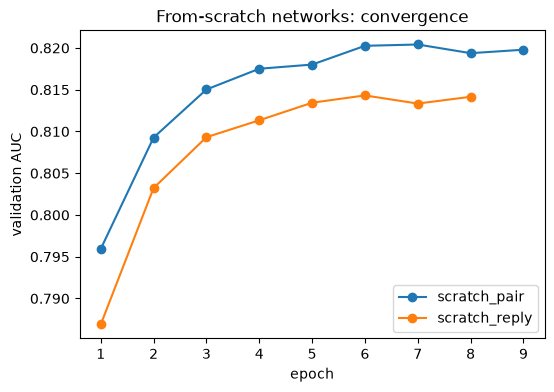

In [2]:
# Training curves
curves = []
for v in ["reply", "pair"]:
    j = U.read_json(U.EXP / f"12_scratch_nn/results/scratch_{v}__sarc_random.json")
    curves.append(pd.DataFrame(j["evals"]).assign(model=f"scratch_{v}"))
    print(f"scratch_{v}: params {j['params']:,}, best epoch {j['best_epoch']}, val AUC {j['val_auc']:.4f}, train {j['train_seconds']/60:.0f} min")
c = pd.concat(curves)
fig, ax = plt.subplots(figsize=(6, 4))
for m, g in c.groupby("model"): ax.plot(g["epoch"], g["val_auc"], marker="o", label=m)
ax.set_xlabel("epoch"); ax.set_ylabel("validation AUC"); ax.legend(); ax.set_title("From-scratch networks: convergence")
U.savefig(fig, "S05_scratch_curves.png"); plt.show()

In [3]:
# Test metrics
M = ["scratch_pair", "scratch_reply", "lgbm_lrscore_cues_contrast", "lgbm_reply_tfidf_surface"]
test, val = U.predictions("sarc_random"); ts, vs = U.predictions("sarc_subreddit")
r = U.evaluate(test, val, M).merge(U.evaluate(ts, vs, M)[["model", "roc_auc"]], on="model", suffixes=("", "_subreddit"))
U.show(r[["label", "roc_auc", "roc_auc_subreddit", "precision", "recall", "f1", "p75_recall"]])

,label,roc_auc,roc_auc_subreddit,precision,recall,f1,p75_recall
0,LightGBM + LR score + cues + contrast,0.8296,0.8226,0.7746,0.7209,0.7468,0.7512
1,"From-scratch ESIM, reply + parent",0.8242,0.8153,0.7485,0.7514,0.7499,0.7433
2,"From-scratch BiLSTM, reply only",0.8180,0.8113,0.7632,0.7144,0.7380,0.7299
3,"LightGBM, + surface (baseline)",0.8074,0.8023,0.7559,0.7023,0.7281,0.7035


## 5.1 Does the parent comment help? (research question Q1)

In [4]:
# Context gain and gap to LightGBM
U.show(pd.concat([U.bootstrap_vs(test, ["scratch_pair"], ref="scratch_reply").assign(set="sarc_random"),
                  U.bootstrap_vs(ts, ["scratch_pair"], ref="scratch_reply").assign(set="sarc_subreddit"),
                  U.bootstrap_vs(test, ["scratch_pair"], ref="lgbm_lrscore_cues_contrast").assign(set="sarc_random")]))

,model,vs,d_auc,ci_low,ci_high,set
0,scratch_pair,scratch_reply,0.0063,0.0050,0.0074,sarc_random
0,scratch_pair,scratch_reply,0.0040,0.0030,0.0051,sarc_subreddit
0,scratch_pair,lgbm_lrscore_cues_contrast,-0.0054,-0.0068,-0.0040,sarc_random


## 5.2 Is it making *different* mistakes?
Correlation of validation residuals (label − calibrated probability). Low correlation means the model is a useful new ensemble member.

In [5]:
# Validation residual correlation
from sklearn.linear_model import LogisticRegression
y = val["label"].to_numpy()
def resid(m):
    x = val[[m]].to_numpy(); x = np.log(np.clip(x, 1e-6, 1 - 1e-6) / (1 - np.clip(x, 1e-6, 1 - 1e-6))) if (x.min() >= 0 and x.max() <= 1) else x
    return y - LogisticRegression().fit(x, y).predict_proba(x)[:, 1]
R = pd.DataFrame({m: resid(m) for m in ["lgbm_lrscore_cues_contrast", "lr_word_char_surface", "ebm_full", "scratch_pair", "scratch_reply"]})
U.show(R.corr(), 3)

,lgbm_lrscore_cues_contrast,lr_word_char_surface,ebm_full,scratch_pair,scratch_reply
lgbm_lrscore_cues_contrast,1.000,0.982,0.987,0.937,0.942
lr_word_char_surface,0.982,1.000,0.994,0.932,0.941
ebm_full,0.987,0.994,1.000,0.937,0.942
scratch_pair,0.937,0.932,0.937,1.000,0.958
scratch_reply,0.942,0.941,0.942,0.958,1.000


## 5.3 Takeaways

- **ESIM (reply + parent) 0.8242**, BiLSTM reply-only 0.8180; the parent adds **+0.0063 [+0.005, +0.0075]** (+0.004 on sarc_subreddit) — twice the hand-made contrast features.
- It is 0.005 below the best compliant LightGBM as a single model, but its errors correlate only 0.93–0.94 with the tree/linear/EBM models (those correlate 0.98–0.99 with each other), which makes it the most valuable new stacking member (step 7).